# TabPFN drift project - Colab runner
Run the cells **top to bottom**. If Colab disconnects, reconnect and run again from cell 2:
finished result files are skipped automatically, so nothing is lost.

**Before you start:** Runtime > Change runtime type > **T4 GPU**.

## 1. Check GPU

In [ ]:
!nvidia-smi -L

## 2. Upload the repo zip and unzip (select `tabpfn-drift.zip` when asked)

In [2]:
import os
from google.colab import files
files.upload()

Saving tabpfn-drift.zip to tabpfn-drift.zip


{'tabpfn-drift.zip': b'PK\x03\x04\x14\x00\x00\x00\x00\x00Y2a]\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\x00\r\x00\x00\x00tabpfn-drift/PK\x03\x04\x14\x00\x00\x00\x08\x00\\2a]a\xc5`\x82a\t\x00\x00K\x13\x00\x00\x16\x00\x00\x00tabpfn-drift/README.md\xadX\x7fo\xdbF\x12\xfd\x9f\x9f\xe2!Aa)!i\xc9\xb1\x81\xab\\\xe7`;N\x1b$q\xd58\xb9+p\xb8\x13W\xe4P\xdc\x13\xb9\xcb\xee.-\xeb\xe2\xf4\xb3\x1ff\x97T$\xb4\x05z\xc0\x19\xb0-rwg\xe7\xe7{3z\x8a\x8fb9\x7f}\x8bN\x15d\x90k\x95S\xebP\x18Y:$ \xb5\x92\x8a0zO\xcd\x92\x0c\xa6\xe3(\xfa\xa9#\xeb\xa4V3\x14\x9a\xecp|E\x0e\x1bm,aS\x91\x82\xab\x08\x85p\xe2\xc8bI\x95\xb8\x97\xba3\xc8+\xa1Vdc\x08U\xa0\xd0\xb0\x8d0\x8eL\x94WZ\xe6d\xa1K<\xcb\xb5r\xf4\xe0`\xf4\xc6>C)\x1f \xdd_\xa3\xe8\xe9S\xbc\x13[\xdd\xb9(\xcb\xb2(\xd7M\xa3\xd51\xef5"wi\xbb\x05\xff\xd8J\x18* \x95#S\x8a\x9c\xf0\x9c\xed\xb1N(g1\xba^\xbc\xbf\xfc9\xc6\xf5\xdd\xdf`\xf3\x8a\x1a1\x06\xf0]\x02E\xf74\xe8\x06QkE\x11k~l\x9d!\xd1\xd8A8\x80SX\xa2\x82\x8a\xde;\xfd\x86\x19lW\x14\xa4b\xac\x8c(:Q\xc70\x94w\xc6H\xb5\x8

In [3]:
!unzip -o -q tabpfn-drift.zip -d /content
%cd /content/tabpfn-drift
!ls

/content/tabpfn-drift
app	eval	   plot_check.py     results		 summarize.py
common	methods    README.md	     run_experiments.py  time_tabpfn.py
data	notebooks  requirements.txt  smoke_test.py


## 3. Install packages (torch is already on Colab)

In [4]:
!pip install -q tabpfn river scikit-learn pandas matplotlib

ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
numba 0.61.2 requires numpy<2.3,>=1.24, but you have numpy 2.5.4 which is incompatible.


## 4. TabPFN access (one-time). Set the token(s) - leave a prompt empty to skip it
**Route A (license key):** open https://ux.priorlabs.ai , log in / register, accept the license
(Licenses tab), copy the API key from the Account page.

**Route B (HuggingFace):** open https://huggingface.co/Prior-Labs/tabpfn_3_5 and accept the terms,
then create a *Read* token at https://huggingface.co/settings/tokens .

Cell 7 tells you if it still fails and which one is missing. Paste whichever you have (both is fine).

In [2]:
import os, getpass
t = getpass.getpass('TABPFN_TOKEN (license key, Enter to skip): ').strip()
if t: os.environ['TABPFN_TOKEN'] = t
h = getpass.getpass('HF_TOKEN (HuggingFace read token, Enter to skip): ').strip()
if h: os.environ['HF_TOKEN'] = h

TABPFN_TOKEN (license key, Enter to skip): ··········
HF_TOKEN (HuggingFace read token, Enter to skip): ··········


## 5. Save results to Google Drive (so they survive disconnects)

In [4]:
from google.colab import drive
drive.mount('/content/drive')
OUT = '/content/drive/MyDrive/tabpfn-drift-results'
os.makedirs(OUT, exist_ok=True)
print('results go to', OUT)

Mounted at /content/drive
results go to /content/drive/MyDrive/tabpfn-drift-results


## 6. Pipeline self-test (fast, no TabPFN) - must end with ALL SMOKE TESTS PASSED

In [7]:
%cd /content/tabpfn-drift
!python smoke_test.py 2>&1 | tail -8

/content/tabpfn-drift
adwin               2.008        2.152              3.0         0.0           1.0            0.000        2
knn                 1.974        3.608             20.0         0.0           0.0           -0.017        2
recency             2.013        2.903             16.5         0.0           0.0            0.002        2
sliding_window      2.154        2.444              4.5         0.0           0.0            0.072        2
validation          2.011        2.350              3.0         0.0           0.0            0.001        2
vanilla             2.008        3.674             20.0         0.0           0.0              NaN        2

ALL SMOKE TESTS PASSED


## 7. Time TabPFN (also confirms the token works)
Read the seconds-per-block for 2000 context rows. One vanilla run = 59 blocks.
If it is more than ~5 s per block, set `CMAX = 1000` in the next cell.

In [8]:
%cd /content/tabpfn-drift
!python time_tabpfn.py

/content/tabpfn-drift
device: cuda Tesla T4

TabPFN requires a one-time license acceptance to download model weights for local inference.

No display detected. Open this URL in a browser on another device:

  https://ux.priorlabs.ai/login?hf_repo_id=tabpfn_3_5

After logging in, accept the license on the Licenses tab,
then copy your API Key from
  https://ux.priorlabs.ai/account

  [c] Copy URL to clipboard    Paste your API key to continue

> tabpfn_sk_wX51ad-LbNgIYvuV1ZtFkgAYrZJR87478W25l3oS_d8
License accepted — API key cached for future sessions.


tabpfn-v3.5-20260909.safetensors: downloading bytes:  27% 237M/876M [00:02<00:02, 214MB/s, 19.8MB/s  ]
tabpfn-v3.5-20260909.safetensors: downloading bytes:  94% 824M/876M [00:03<00:00, 355MB/s, 69.1MB/s  ]
tabpfn-v3.5-20260909.safetensors: reconstructing file:  77% 671M/876M [00:04<00:01, 157MB/s, 18.9MB/s  ]
tabpfn-v3.5-20260909.safetensors: downloading bytes: 100% 830M/830M [00:07<00:00, 108MB/s, 69.9MB/s  ]
tabpfn-v3.5-20260909.safete

## 8. Settings used by all runs below

In [9]:
CMAX = 2000          # lower to 1000 if cell 7 was slow
SEEDS = '0 1 2'

## 9. FIRST RESULTS for your teammate: vanilla + sliding window on sudden + none
Takes a while. When done, send her the Drive folder (or download the CSVs).

In [10]:
!python run_experiments.py --streams sudden none --seeds {SEEDS} --methods vanilla sliding_window --c-max {CMAX} --out {OUT}

12 runs | model=tabpfn c_max=2000 blocks=60x200 -> /content/drive/MyDrive/tabpfn-drift-results/
[1/12] stream=sudden seed=0 method=vanilla
    block  10/59  rmse=1.126  ctx=2000  elapsed=15s
    block  20/59  rmse=1.056  ctx=2000  elapsed=34s
    block  30/59  rmse=6.540  ctx=2000  elapsed=54s
    block  40/59  rmse=4.948  ctx=2000  elapsed=74s
    block  50/59  rmse=4.762  ctx=2000  elapsed=94s
    block  59/59  rmse=3.737  ctx=2000  elapsed=112s
  saved: /content/drive/MyDrive/tabpfn-drift-results/sudden_0_vanilla.csv  (mean rmse 3.099, 112s)
[2/12] stream=sudden seed=0 method=sliding_window
    block  10/59  rmse=1.141  ctx=1000  elapsed=12s
    block  20/59  rmse=1.086  ctx=1000  elapsed=25s
    block  30/59  rmse=6.557  ctx=1000  elapsed=38s
    block  40/59  rmse=1.054  ctx=1000  elapsed=51s
    block  50/59  rmse=1.013  ctx=1000  elapsed=64s
    block  59/59  rmse=1.041  ctx=1000  elapsed=76s
  saved: /content/drive/MyDrive/tabpfn-drift-results/sudden_0_sliding_window.csv  (mean

## 10. GO / NO-GO check: does vanilla TabPFN get worse after the sudden drift?

saved check_sudden.png


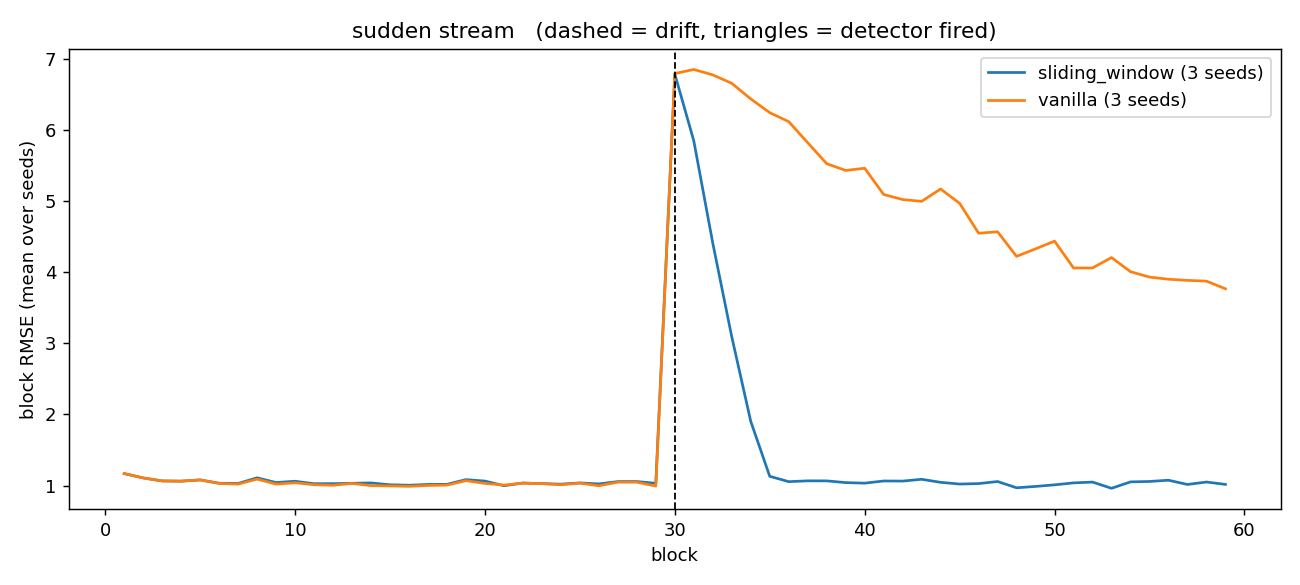

In [11]:
!python plot_check.py --results {OUT} --stream sudden --methods vanilla sliding_window --out check_sudden.png
from IPython.display import Image
Image('check_sudden.png')

**Read the plot.** Vanilla RMSE should jump after the dashed line (block 30) and stay high
for many blocks. If it barely moves, the project's premise is weak: tell your teammate and
increase the drift severity before running more.

## 11. Remaining policies on sudden + none (P2 recency, P3 ADWIN)

In [12]:
!python run_experiments.py --streams sudden none --seeds {SEEDS} --methods recency adwin --c-max {CMAX} --out {OUT}

12 runs | model=tabpfn c_max=2000 blocks=60x200 -> /content/drive/MyDrive/tabpfn-drift-results/
[1/12] stream=sudden seed=0 method=recency
    block  10/59  rmse=1.126  ctx=2000  elapsed=14s
    block  20/59  rmse=1.061  ctx=2000  elapsed=34s
    block  30/59  rmse=6.573  ctx=2000  elapsed=53s
    block  40/59  rmse=2.484  ctx=2000  elapsed=73s
    block  50/59  rmse=1.248  ctx=2000  elapsed=93s
    block  59/59  rmse=1.020  ctx=2000  elapsed=111s
  saved: /content/drive/MyDrive/tabpfn-drift-results/sudden_0_recency.csv  (mean rmse 1.825, 111s)
[2/12] stream=sudden seed=0 method=adwin
    block  10/59  rmse=1.126  ctx=2000  elapsed=13s
    block  20/59  rmse=1.056  ctx=2000  elapsed=33s
    block  30/59  rmse=6.540  ctx=2000  elapsed=54s
    block  40/59  rmse=1.021  ctx=2000  elapsed=67s
    block  50/59  rmse=0.968  ctx=2000  elapsed=88s
    block  59/59  rmse=1.017  ctx=2000  elapsed=107s
  saved: /content/drive/MyDrive/tabpfn-drift-results/sudden_0_adwin.csv  (mean rmse 1.132, 107s

## 12. P4 validation-guided (about 5x slower per run) + kNN baseline on sudden + none

In [13]:
!python run_experiments.py --streams sudden none --seeds {SEEDS} --methods validation knn --c-max {CMAX} --out {OUT}

12 runs | model=tabpfn c_max=2000 blocks=60x200 -> /content/drive/MyDrive/tabpfn-drift-results/
[1/12] stream=sudden seed=0 method=validation
    block  10/59  rmse=1.126  ctx=2000  elapsed=52s
    block  20/59  rmse=1.058  ctx=2000  elapsed=126s
    block  30/59  rmse=6.590  ctx=2000  elapsed=201s
    block  40/59  rmse=1.075  ctx=600  elapsed=268s
    block  50/59  rmse=1.002  ctx=1600  elapsed=339s
    block  59/59  rmse=1.034  ctx=1600  elapsed=404s
  saved: /content/drive/MyDrive/tabpfn-drift-results/sudden_0_validation.csv  (mean rmse 1.322, 404s)
[2/12] stream=sudden seed=0 method=knn
    block  10/59  rmse=1.126  ctx=2000  elapsed=14s
    block  20/59  rmse=1.068  ctx=2000  elapsed=35s
    block  30/59  rmse=6.629  ctx=2000  elapsed=57s
    block  40/59  rmse=4.879  ctx=2000  elapsed=78s
    block  50/59  rmse=4.483  ctx=2000  elapsed=100s
    block  59/59  rmse=3.626  ctx=2000  elapsed=119s
  saved: /content/drive/MyDrive/tabpfn-drift-results/sudden_0_knn.csv  (mean rmse 3.075

## 13. All remaining streams (gradual, recurring) for every method

In [14]:
!python run_experiments.py --streams gradual recurring --seeds {SEEDS} --methods vanilla sliding_window recency adwin validation knn --c-max {CMAX} --out {OUT}

36 runs | model=tabpfn c_max=2000 blocks=60x200 -> /content/drive/MyDrive/tabpfn-drift-results/
[1/36] stream=gradual seed=0 method=vanilla
    block  10/59  rmse=1.126  ctx=2000  elapsed=15s
    block  20/59  rmse=1.452  ctx=2000  elapsed=35s
    block  30/59  rmse=4.384  ctx=2000  elapsed=55s
    block  40/59  rmse=4.880  ctx=2000  elapsed=76s
    block  50/59  rmse=4.643  ctx=2000  elapsed=97s
    block  59/59  rmse=3.605  ctx=2000  elapsed=116s
  saved: /content/drive/MyDrive/tabpfn-drift-results/gradual_0_vanilla.csv  (mean rmse 3.331, 116s)
[2/36] stream=gradual seed=0 method=sliding_window
    block  10/59  rmse=1.141  ctx=1000  elapsed=12s
    block  20/59  rmse=1.472  ctx=1000  elapsed=24s
    block  30/59  rmse=3.734  ctx=1000  elapsed=37s
    block  40/59  rmse=1.314  ctx=1000  elapsed=50s
    block  50/59  rmse=1.013  ctx=1000  elapsed=63s
    block  59/59  rmse=1.041  ctx=1000  elapsed=75s
  saved: /content/drive/MyDrive/tabpfn-drift-results/gradual_0_sliding_window.csv  (

## 14. Summary table + plots

In [15]:
!python summarize.py {OUT}
!python plot_check.py --results {OUT} --stream sudden --out check_sudden.png
!python plot_check.py --results {OUT} --stream gradual --out check_gradual.png
!python plot_check.py --results {OUT} --stream recurring --out check_recurring.png

                rmse_gradual  rmse_none  rmse_recurring  rmse_sudden  recovery_gradual  recovery_recurring  recovery_sudden  flags_gradual  flags_none  flags_recurring  flags_sudden  \
method                                                                                                                                                                                  
adwin                  2.129      1.031           1.354        1.132            20.000               1.889            2.000            2.0         0.0              3.0           1.0   
knn                    3.282      1.035           3.402        3.044            20.000              15.000           30.000            0.0         0.0              0.0           0.0   
recency                2.146      1.029           2.940        1.803            14.000              15.000           20.333            0.0         0.0              0.0           0.0   
sliding_window         1.794      1.043           1.895        1.329       

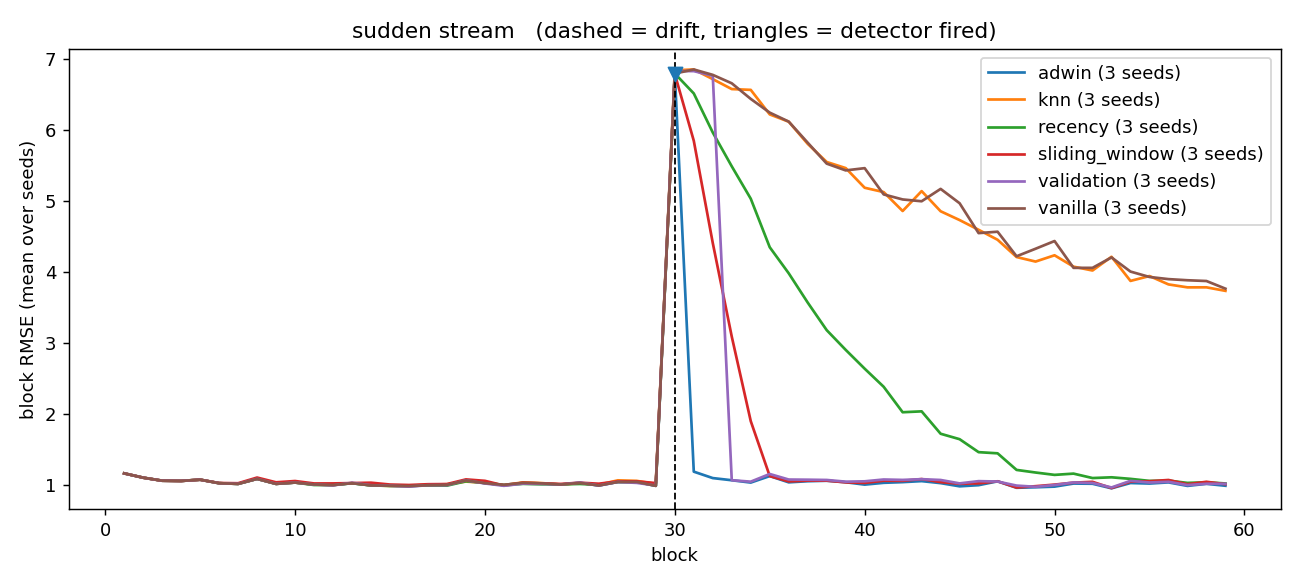

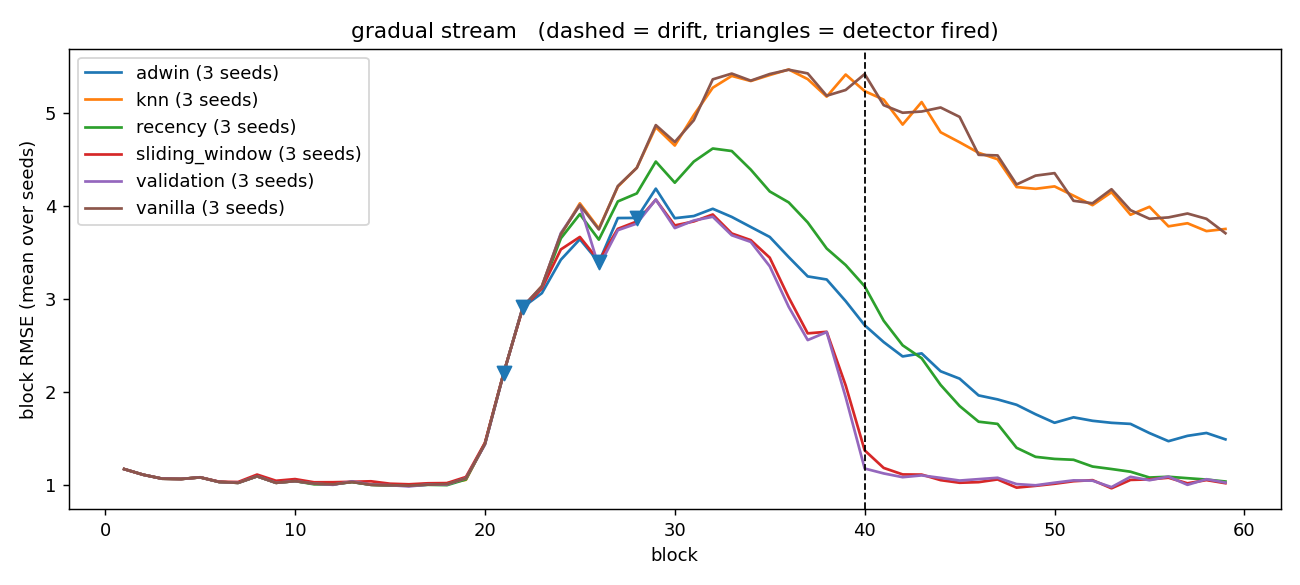

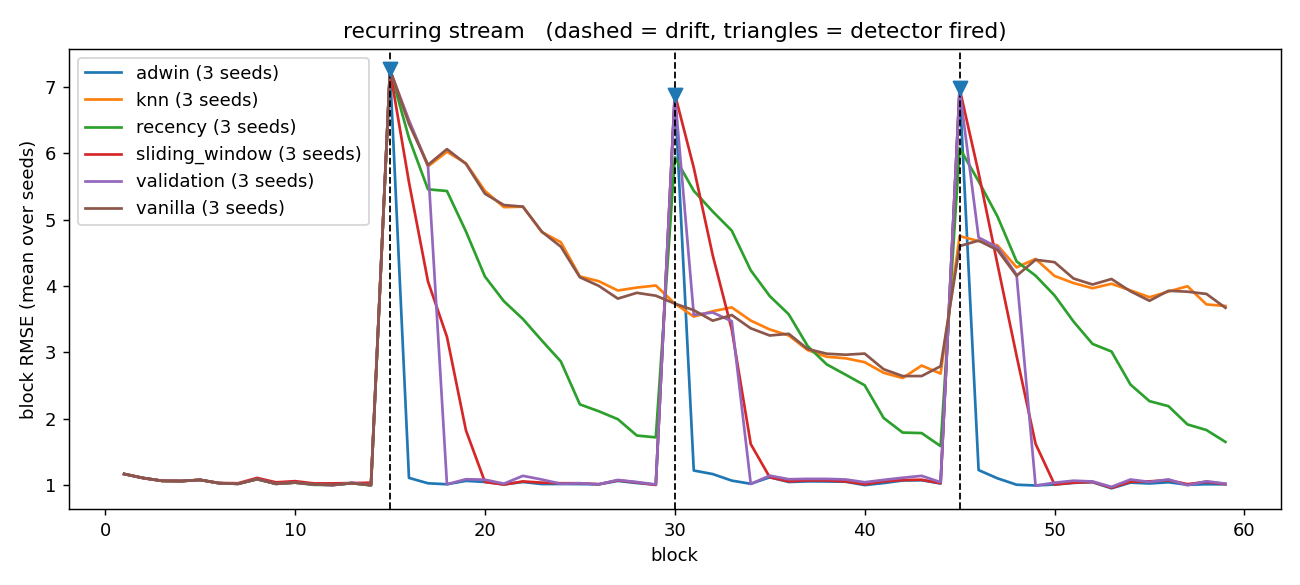

In [16]:
from IPython.display import Image, display
for s in ['sudden', 'gradual', 'recurring']:
    display(Image(f'check_{s}.png'))

In [1]:
import torch

print("CUDA available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))

CUDA available: True
GPU: Tesla T4


In [6]:
!pip install -q "numpy>=1.24,<2.3"

In [1]:
import numpy
import torch

print("NumPy:", numpy.__version__)
print("CUDA:", torch.cuda.is_available())

NumPy: 2.2.6
CUDA: True
